In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from google.colab import drive



In [ ]:
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os


print(os.listdir('/content/drive/MyDrive'))

['IMG_1375.PNG', 'Classroom', 'Simplifier par la méthode des diagrammes de Karna....gsheet', 'Copy of Hobbies, interests, and leisure activities - German - Foreign Language - 6th grade by Slidego (1).gslides', 'Copy of Hobbies, interests, and leisure activities - German - Foreign Language - 6th grade by Slidego.gslides', "Objectif : Simplifier l'expression logique en som....gsheet", 'AU-2023-Tech-Mult-Chaptre-1 (1).pdf', 'IMG_1960.JPG', '04b_asl_predictions.ipynb', 'vision 17.gdoc', "Movin'T vision 17.pptx", 'IMG_2298.jpeg', 'give me simple datas to built with python classif....gsheet', 'Colab Notebooks', 'Copy of All About Street Vehicles by Slidesgo.gslides', 'Copy of Body Language Workshop by Slidesgo.gslides', 'SPONSO IASTAM 6.0.pdf', 'Examen Technologie Multimédias CS.zip', 'Pourquoi devenir partenaire de l’IASTAM 6.gdoc', 'Jobs fairs.gdoc', 'jobs fairs 2026 sponsp.gdoc', 'SPONSO IASTAM 6.0.xlsx', 'SPONSO IASTAM 6.0.gsheet', 'Untitled document (3).gdoc', 'Untitled document (2).g

In [ ]:
import zipfile

zip_path = "/content/drive/MyDrive/archive (2).zip"
extract_path = "/content/Pneumonia_Project"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction terminée !")

Extraction terminée !


In [ ]:
import os

print(os.listdir(extract_path))

['val', 'chest_xray', '__MACOSX', 'test', 'train']


In [ ]:
import os

dataset_path = "/content/Pneumonia_Project/chest_xray"

for folder in ["train", "test", "val"]:
    print(f"\n{folder.upper()}")

    for category in ["NORMAL", "PNEUMONIA"]:
        path = os.path.join(dataset_path, folder, category)

        images = os.listdir(path)

        print(f"{category}: {len(images)} images")


TRAIN
NORMAL: 1341 images
PNEUMONIA: 3875 images

TEST
NORMAL: 234 images
PNEUMONIA: 390 images

VAL
NORMAL: 8 images
PNEUMONIA: 8 images


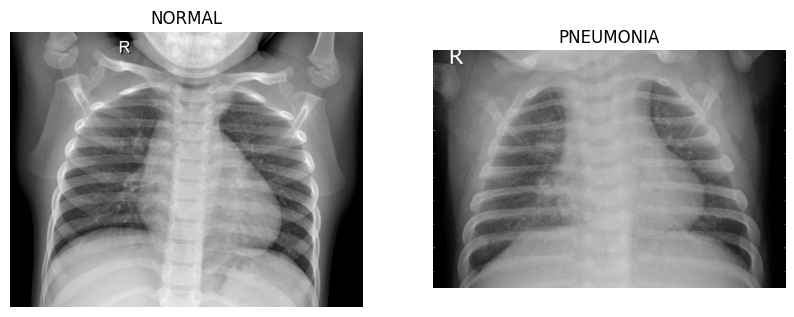

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os

normal_path = os.path.join(
    dataset_path, "train", "NORMAL"
)

pneumonia_path = os.path.join(
    dataset_path, "train", "PNEUMONIA"
)

normal_image = os.listdir(normal_path)[0]
pneumonia_image = os.listdir(pneumonia_path)[0]

#**************************************************************

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

img1 = Image.open(os.path.join(normal_path, normal_image))
img2 = Image.open(os.path.join(pneumonia_path, pneumonia_image))

axes[0].imshow(img1, cmap="gray")
axes[0].set_title("NORMAL")
axes[0].axis("off")

axes[1].imshow(img2, cmap="gray")
axes[1].set_title("PNEUMONIA")
axes[1].axis("off")

plt.show()

In [ ]:
print("NORMAL")
print("Dimensions :", img1.size)
print("Mode :", img1.mode)
print("Format :", img1.format)

print("\nPNEUMONIA")
print("Dimensions :", img2.size)
print("Mode :", img2.mode)
print("Format :", img2.format)

NORMAL
Dimensions : (1766, 1380)
Mode : L
Format : JPEG

PNEUMONIA
Dimensions : (936, 632)
Mode : L
Format : JPEG


In [ ]:

from collections import Counter
from PIL import Image
import os

dimensions = []

for category in ["NORMAL", "PNEUMONIA"]:
    path = os.path.join(dataset_path, "train", category)

    for filename in os.listdir(path):
        image_path = os.path.join(path, filename)

        try:
            img = Image.open(image_path)
            dimensions.append(img.size)
        except:
            continue

print("Nombre de dimensions différentes :",
      len(set(dimensions)))

print("\nLes 10 dimensions les plus fréquentes :")

for size, count in Counter(dimensions).most_common(10):
    print(size, ":", count, "images")


Nombre de dimensions différentes : 4366

Les 10 dimensions les plus fréquentes :
(1072, 648) : 7 images
(1080, 728) : 6 images
(1216, 872) : 5 images
(1008, 704) : 5 images
(1008, 680) : 5 images
(976, 672) : 5 images
(1064, 760) : 5 images
(992, 592) : 5 images
(1304, 968) : 4 images
(1136, 680) : 4 images


In [ ]:

import numpy as np

widths = [w for w, h in dimensions]
heights = [h for w, h in dimensions]

print("Largeur minimale :", min(widths))
print("Largeur maximale :", max(widths))
print("Largeur moyenne :", np.mean(widths))

print("\nHauteur minimale :", min(heights))
print("Hauteur maximale :", max(heights))
print("Hauteur moyenne :", np.mean(heights))


Largeur minimale : 384
Largeur maximale : 2916
Largeur moyenne : 1320.6108128834355

Hauteur minimale : 127
Hauteur maximale : 2663
Hauteur moyenne : 968.0747699386503


In [ ]:
from collections import Counter
import os
from PIL import Image

modes = Counter()

for category in ["NORMAL", "PNEUMONIA"]:
    path = os.path.join(dataset_path, "train", category)

    for filename in os.listdir(path):
        try:
            img = Image.open(os.path.join(path, filename))
            modes[img.mode] += 1
        except:
            continue

print("Distribution des modes :")
for mode, count in modes.items():
    print(mode, ":", count)

Distribution des modes :
L : 4933
RGB : 283


In [ ]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    f"{dataset_path}/train",
    validation_split=0.2, subset="training", seed=42,
    image_size=IMG_SIZE, batch_size=BATCH,
    color_mode="rgb", label_mode="binary")

val_ds = tf.keras.utils.image_dataset_from_directory(
    f"{dataset_path}/train",
    validation_split=0.2, subset="validation", seed=42,
    image_size=IMG_SIZE, batch_size=BATCH,
    color_mode="rgb", label_mode="binary")

test_ds = tf.keras.utils.image_dataset_from_directory(
    f"{dataset_path}/test",
    image_size=IMG_SIZE, batch_size=BATCH,
    color_mode="rgb", label_mode="binary", shuffle=False)

print(train_ds.class_names)   # ['NORMAL', 'PNEUMONIA'] -> 0 et 1

Found 5216 files belonging to 2 classes.
Using 4173 files for training.
Found 5216 files belonging to 2 classes.
Using 1043 files for validation.
Found 624 files belonging to 2 classes.
['NORMAL', 'PNEUMONIA']


In [ ]:
import os

n_normal, n_pneu = len(os.listdir(os.path.join(dataset_path,"train","NORMAL"))), len(os.listdir(os.path.join(dataset_path,"train","PNEUMONIA")))
total = n_normal + n_pneu

class_weight = {
    0: total / (2 * n_normal),   # ~1.94
    1: total / (2 * n_pneu),     # ~0.67
}

NameError: name 'dataset_path' is not defined

In [ ]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

base = MobileNetV2(input_shape=(224, 224, 3),
                   include_top=False, weights="imagenet")
base.trainable = False     # on gèle les poids déjà appris

augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
])

inputs = layers.Input(shape=(224, 224, 3))
x = augmentation(inputs)
x = preprocess_input(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy",
             tf.keras.metrics.Recall(name="recall"),
             tf.keras.metrics.Precision(name="precision")])

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                     restore_best_weights=True),
]

history = model.fit(train_ds, validation_data=val_ds,
                    epochs=10, class_weight=class_weight,
                    callbacks=callbacks)

Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 64s 374ms/step - accuracy: 0.8574 - loss: 0.3380 - precision: 0.9550 - recall: 0.8468 - val_accuracy: 0.9386 - val_loss: 0.1792 - val_precision: 0.9517 - val_recall: 0.9685
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 45s 341ms/step - accuracy: 0.9176 - loss: 0.2042 - precision: 0.9744 - recall: 0.9124 - val_accuracy: 0.9444 - val_loss: 0.1565 - val_precision: 0.9577 - val_recall: 0.9698
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 43s 327ms/step - accuracy: 0.9360 - loss: 0.1737 - precision: 0.9805 - recall: 0.9318 - val_accuracy: 0.9511 - val_loss: 0.1446 - val_precision: 0.9745 - val_recall: 0.9610
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 44s 332ms/step - accuracy: 0.9351 - loss: 0.1580 - precision: 0.9841 - recall: 0.9270 - val_accuracy: 0.9521 - val_loss: 0.1390 - val_precision: 0.9794 - val_recall: 0.9572
Epoch 5/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 45s 340ms/step - accuracy: 0.9408 - loss: 0.1449 - precision: 0.9859 - recall: 0.9331 - val_accuracy: 0.9358

In [ ]:
model.save("/content/drive/MyDrive/pneumonia_model.keras")

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

print(model.evaluate(test_ds))

y_true = np.concatenate([y.numpy() for _, y in test_ds]).ravel()
y_prob = model.predict(test_ds).ravel()
y_pred = (y_prob > 0.5).astype(int)

print(confusion_matrix(y_true, y_pred))
print(classification_report(y_true, y_pred,
                            target_names=["NORMAL", "PNEUMONIA"]))

20/20 ━━━━━━━━━━━━━━━━━━━━ 221s 11s/step - accuracy: 0.8381 - loss: 0.3941 - precision: 0.8017 - recall: 0.9846
[0.3941449522972107, 0.8381410241127014, 0.9846153855323792, 0.8016701340675354]
20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 270ms/step
[[139  95]
 [  6 384]]
              precision    recall  f1-score   support

      NORMAL       0.96      0.59      0.73       234
   PNEUMONIA       0.80      0.98      0.88       390

    accuracy                           0.84       624
   macro avg       0.88      0.79      0.81       624
weighted avg       0.86      0.84      0.83       624



In [ ]:
from sklearn.metrics import recall_score, precision_score

print("seuil | recall PNEUMONIA | recall NORMAL | faux négatifs | faux positifs")
for seuil in [0.5, 0.6, 0.7, 0.8, 0.9]:
    pred = (y_prob > seuil).astype(int)
    rec_pneu = recall_score(y_true, pred, pos_label=1)
    rec_norm = recall_score(y_true, pred, pos_label=0)
    fn = int(((y_true == 1) & (pred == 0)).sum())
    fp = int(((y_true == 0) & (pred == 1)).sum())
    print(f"{seuil:.1f}   | {rec_pneu:.2f}             | {rec_norm:.2f}          | {fn:3d}           | {fp:3d}")

seuil | recall PNEUMONIA | recall NORMAL | faux négatifs | faux positifs
0.5   | 0.98             | 0.59          |   6           |  95
0.6   | 0.98             | 0.64          |   9           |  85
0.7   | 0.96             | 0.70          |  17           |  70
0.8   | 0.95             | 0.79          |  21           |  48
0.9   | 0.92             | 0.86          |  31           |  32


In [ ]:
model.save("/content/drive/MyDrive/pneumonia_model.keras")

In [ ]:
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy",
             tf.keras.metrics.Recall(name="recall"),
             tf.keras.metrics.Precision(name="precision")])

print(sum(l.trainable for l in base.layers), "couches dégelées")

30 couches dégelées


In [ ]:
callbacks_ft = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True)
]

history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weight,
    callbacks=callbacks_ft)

Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 82s 513ms/step - accuracy: 0.9183 - loss: 0.2793 - precision: 0.9371 - recall: 0.9533 - val_accuracy: 0.9569 - val_loss: 0.1372 - val_precision: 0.9573 - val_recall: 0.9874
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 51s 387ms/step - accuracy: 0.9348 - loss: 0.1644 - precision: 0.9812 - recall: 0.9296 - val_accuracy: 0.9636 - val_loss: 0.1222 - val_precision: 0.9678 - val_recall: 0.9849
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 48s 365ms/step - accuracy: 0.9422 - loss: 0.1455 - precision: 0.9814 - recall: 0.9396 - val_accuracy: 0.9655 - val_loss: 0.1111 - val_precision: 0.9773 - val_recall: 0.9773
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 49s 371ms/step - accuracy: 0.9480 - loss: 0.1319 - precision: 0.9858 - recall: 0.9432 - val_accuracy: 0.9664 - val_loss: 0.1071 - val_precision: 0.9798 - val_recall: 0.9761
Epoch 5/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 51s 389ms/step - accuracy: 0.9478 - loss: 0.1248 - precision: 0.9857 - recall: 0.9429 - val_accuracy: 0.9664

In [ ]:
model.save("/content/drive/MyDrive/pneumonia_model_v2.keras")

y_prob = model.predict(test_ds).ravel()
y_pred = (y_prob > 0.5).astype(int)
print(confusion_matrix(y_true, y_pred))
print(classification_report(y_true, y_pred,
                            target_names=["NORMAL", "PNEUMONIA"]))

20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 223ms/step
[[145  89]
 [  6 384]]
              precision    recall  f1-score   support

      NORMAL       0.96      0.62      0.75       234
   PNEUMONIA       0.81      0.98      0.89       390

    accuracy                           0.85       624
   macro avg       0.89      0.80      0.82       624
weighted avg       0.87      0.85      0.84       624



In [ ]:
print(tf.__version__)

2.21.0


In [ ]:
y_prob = model.predict(test_ds).ravel()

20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 201ms/step


In [ ]:
print(os.path.exists("/content/drive/MyDrive/pneumonia_model_v2.keras"))

True


In [ ]:
print(os.path.exists("/content/drive/MyDrive/pneumonia_model_v2.keras"))

True


In [ ]:
import os
import shutil
from google.colab import files

dossier = "/content/echantillon"
os.makedirs(dossier, exist_ok=True)

for categorie in ["NORMAL", "PNEUMONIA"]:
    chemin = os.path.join(dataset_path, "test", categorie)
    vrais = [f for f in os.listdir(chemin) if not f.startswith("._")][:3]
    for nom in vrais:
        shutil.copy(os.path.join(chemin, nom), os.path.join(dossier, f"{categorie}_{nom}"))

shutil.make_archive("/content/echantillon", "zip", dossier)
files.download("/content/echantillon.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import numpy as np
import tensorflow as tf
from sklearn.metrics import recall_score, confusion_matrix, classification_report

dataset_path = "/content/Pneumonia_Project/chest_xray"
model = tf.keras.models.load_model("/content/drive/MyDrive/pneumonia_model_v2.keras")

In [ ]:
val_ds = tf.keras.utils.image_dataset_from_directory(
    f"{dataset_path}/train",
    validation_split=0.2, subset="validation", seed=42,
    image_size=(224, 224), batch_size=32,
    color_mode="rgb", label_mode="binary")

Found 5216 files belonging to 2 classes.
Using 1043 files for validation.


In [ ]:
y_true_val = []
y_prob_val = []

for images, labels in val_ds:
    probs = model.predict(images, verbose=0).ravel()
    y_prob_val.extend(probs)
    y_true_val.extend(labels.numpy().ravel())

y_true_val = np.array(y_true_val)
y_prob_val = np.array(y_prob_val)
print(len(y_true_val), "images de validation")

1043 images de validation


In [ ]:
print("seuil | recall PNEUMONIA | faux négatifs | faux positifs")

meilleur = None
for seuil in np.arange(0.30, 0.96, 0.05):
    seuil = round(float(seuil), 2)
    pred = (y_prob_val > seuil).astype(int)
    rec = recall_score(y_true_val, pred, pos_label=1)
    fn = int(((y_true_val == 1) & (pred == 0)).sum())
    fp = int(((y_true_val == 0) & (pred == 1)).sum())
    print(f"{seuil:.2f}  | {rec:.3f}            | {fn:4d}          | {fp:4d}")
    if rec >= 0.95:
        meilleur = seuil

print("\nSeuil le plus haut avec recall >= 0.95 :", meilleur)

seuil | recall PNEUMONIA | faux négatifs | faux positifs
0.30  | 0.981            |   15          |   20
0.35  | 0.979            |   17          |   17
0.40  | 0.975            |   20          |   15
0.45  | 0.974            |   21          |   14
0.50  | 0.974            |   21          |   14
0.55  | 0.969            |   25          |   12
0.60  | 0.967            |   26          |   12
0.65  | 0.963            |   29          |   11
0.70  | 0.961            |   31          |   11
0.75  | 0.955            |   36          |   10
0.80  | 0.948            |   41          |   10
0.85  | 0.942            |   46          |   10
0.90  | 0.933            |   53          |    7
0.95  | 0.913            |   69          |    3

Seuil le plus haut avec recall >= 0.95 : 0.75


In [ ]:
SEUIL = meilleur   # le seuil choisi à la cellule 4

test_ds = tf.keras.utils.image_dataset_from_directory(
    f"{dataset_path}/test",
    image_size=(224, 224), batch_size=32,
    color_mode="rgb", label_mode="binary", shuffle=False)

y_true = np.concatenate([y.numpy() for _, y in test_ds]).ravel()
y_prob = model.predict(test_ds).ravel()
y_pred = (y_prob > SEUIL).astype(int)

print(confusion_matrix(y_true, y_pred))
print(classification_report(y_true, y_pred,
                            target_names=["NORMAL", "PNEUMONIA"]))

Found 624 files belonging to 2 classes.
20/20 ━━━━━━━━━━━━━━━━━━━━ 8s 268ms/step
[[167  67]
 [ 12 378]]
              precision    recall  f1-score   support

      NORMAL       0.93      0.71      0.81       234
   PNEUMONIA       0.85      0.97      0.91       390

    accuracy                           0.87       624
   macro avg       0.89      0.84      0.86       624
weighted avg       0.88      0.87      0.87       624



In [ ]:
import shutil
from google.colab import files

shutil.make_archive("/content/test_complet", "zip", f"{dataset_path}/test")
files.download("/content/test_complet.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>